# EDA: Predicting Airline Satisfaction (A)

Mục tiêu: hiểu dữ liệu để cả nhóm biết cột nào quan trọng, có gì bất thường, và gợi ý feature cho B.

1. Tổng quan và target
2. Cột category
3. 13 cột điểm dịch vụ (0-5)
4. Cột số: tuổi, quãng đường, delay
5. Độ mạnh từng cột: AUC khi dùng riêng một cột
6. Tương quan giữa các cột
7. Tương tác giữa các cột category
8. Adversarial validation: train và test có giống nhau không

Hình được lưu vào `reports/figures/` để dùng cho báo cáo. Phần tóm tắt ở cuối notebook.

In [1]:
import sys
sys.path.append("../src")
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from config import CAT_COLS, DATA_DIR, NUM_COLS, SCORE_COLS, TARGET

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)

# Bảng màu: một màu xanh cho tỉ lệ, xám cho đường tham chiếu
BLUE, BLUE_LIGHT, REF = "#2a78d6", "#9ec5f4", "#898781"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": "#0b0b0b",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "figure.dpi": 110, "savefig.bbox": "tight",
})

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150)

## 1. Tổng quan và target

In [2]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
train[TARGET] = train[TARGET].astype(int)
y = train[TARGET].values
BASE = y.mean()

print(f"train {train.shape}, test {test.shape}")
print(f"Tỉ lệ hài lòng: {BASE:.2%}")
print("Giá trị thiếu (train):", train.isna().sum()[lambda s: s > 0].to_dict())
print("Giá trị thiếu (test): ", test.isna().sum()[lambda s: s > 0].to_dict())

train (699635, 23), test (299844, 22)
Tỉ lệ hài lòng: 44.36%
Giá trị thiếu (train): {'Arrival Delay in Minutes': 292}
Giá trị thiếu (test):  {'Arrival Delay in Minutes': 130}


### 5 dòng đầu của train

In [3]:
train.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,1
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,0
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,0


### Kiểu dữ liệu, số giá trị khác nhau, giá trị thiếu

In [4]:
pd.DataFrame({
    "kiểu": train.dtypes.astype(str),
    "số giá trị khác nhau": train.nunique(),
    "thiếu (train)": train.isna().sum(),
    "thiếu (test)": test.reindex(columns=train.columns).isna().sum(),
    "ví dụ": train.iloc[0],
})

,kiểu,số giá trị khác nhau,thiếu (train),thiếu (test),ví dụ
id,int64,699635,0,0,0
Age,int64,75,0,0,36
Flight Distance,int64,3474,0,0,694
Inflight wifi service,int64,6,0,0,4
Departure/Arrival time convenient,int64,6,0,0,4
Ease of Online booking,int64,6,0,0,4
Gate location,int64,6,0,0,3
Food and drink,int64,6,0,0,1
Online boarding,int64,6,0,0,4
Seat comfort,int64,6,0,0,1


### Thống kê các cột số (train)

In [5]:
train[NUM_COLS + SCORE_COLS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,699635.0,39.00,13.80,7.0,27.0,40.0,50.0,85.0
Flight Distance,699635.0,1353.78,954.42,67.0,631.0,954.0,1814.0,4983.0
Departure Delay in Minutes,699635.0,1.18,5.98,0.0,0.0,0.0,0.0,489.0
Arrival Delay in Minutes,699343.0,1.13,5.75,0.0,0.0,0.0,0.0,491.0
Inflight wifi service,699635.0,2.78,1.28,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,699635.0,3.16,1.48,0.0,2.0,3.0,4.0,5.0
Ease of Online booking,699635.0,2.81,1.33,0.0,2.0,3.0,4.0,5.0
Gate location,699635.0,3.01,1.25,0.0,2.0,3.0,4.0,5.0
Food and drink,699635.0,3.27,1.30,0.0,2.0,3.0,4.0,5.0
Online boarding,699635.0,3.36,1.29,0.0,2.0,4.0,4.0,5.0


### Các cột chữ (train)

In [6]:
train[CAT_COLS].describe().T

,count,unique,top,freq
Gender,699635,2,Male,351683
Customer Type,699635,2,Loyal Customer,576990
Type of Travel,699635,2,Business travel,497441
Class,699635,3,Business,342212


### So sánh trung bình train và test (để thấy hai bên có giống nhau không)

In [7]:
pd.DataFrame({"train": train[NUM_COLS + SCORE_COLS].mean(),
              "test": test[NUM_COLS + SCORE_COLS].mean()}).assign(
    chênh=lambda d: d["test"] - d["train"]).round(3)

,train,test,chênh
Age,39.002,38.993,-0.009
Flight Distance,1353.779,1353.369,-0.410
Departure Delay in Minutes,1.176,1.157,-0.020
Arrival Delay in Minutes,1.134,1.120,-0.014
Inflight wifi service,2.779,2.777,-0.002
Departure/Arrival time convenient,3.156,3.152,-0.005
Ease of Online booking,2.813,2.813,-0.001
Gate location,3.014,3.013,-0.001
Food and drink,3.266,3.270,0.004
Online boarding,3.364,3.366,0.002


## 2. Cột category

Thanh là tỉ lệ hài lòng theo từng giá trị; đường xám là tỉ lệ chung của toàn bộ train. Chữ cạnh thanh là tỉ lệ và số dòng.

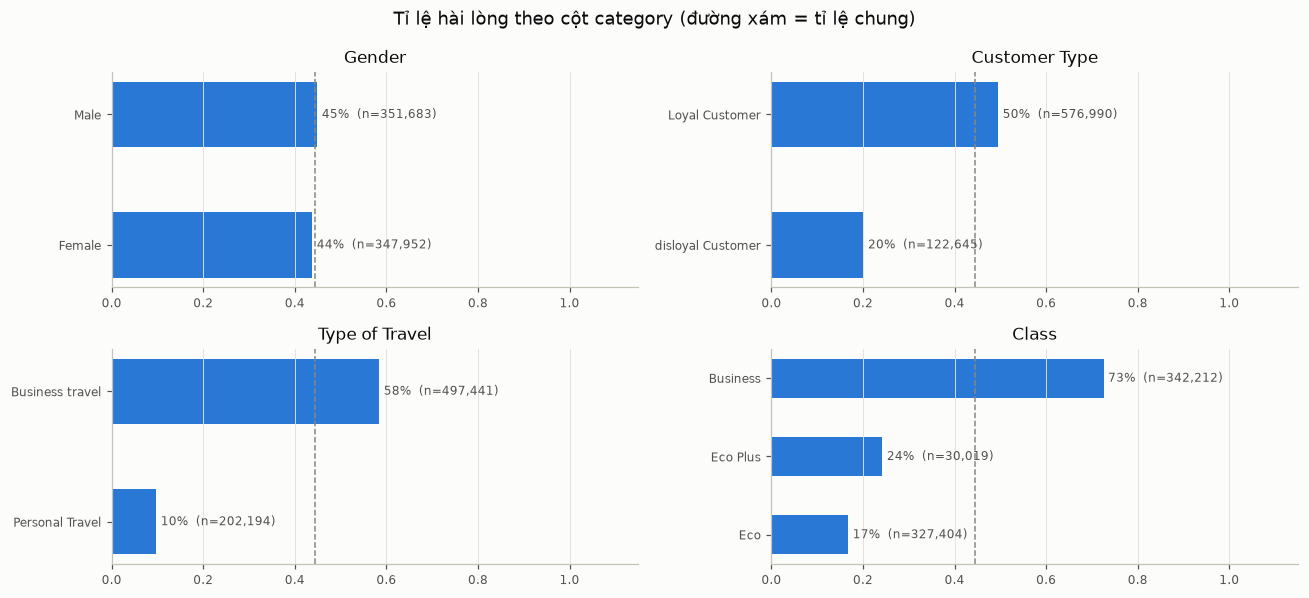

          rate       n
Gender                
Female  0.4380  347952
Male    0.4491  351683 

                     rate       n
Customer Type                    
Loyal Customer     0.4951  576990
disloyal Customer  0.2009  122645 

                   rate       n
Type of Travel                 
Business travel  0.5843  497441
Personal Travel  0.0973  202194 

            rate       n
Class                   
Business  0.7253  342212
Eco       0.1676  327404
Eco Plus  0.2422   30019 



In [8]:
def rate_table(col, df=train):
    g = df.groupby(col, observed=True)[TARGET].agg(rate="mean", n="size")
    return g

fig, axes = plt.subplots(2, 2, figsize=(12, 5.5))
for ax, col in zip(axes.flat, CAT_COLS):
    t = rate_table(col).sort_values("rate")
    ax.barh(t.index.astype(str), t["rate"], color=BLUE, height=0.5)
    ax.axvline(BASE, color=REF, lw=1, ls="--")
    for i, (r, n) in enumerate(zip(t["rate"], t["n"])):
        ax.text(r + 0.01, i, f"{r:.0%}  (n={n:,})", va="center", fontsize=8, color="#52514e")
    ax.set_xlim(0, 1.15)
    ax.set_title(col)
    ax.grid(axis="y", visible=False)
fig.suptitle("Tỉ lệ hài lòng theo cột category (đường xám = tỉ lệ chung)")
fig.tight_layout()
save(fig, "01_category_rate")
plt.show()

for col in CAT_COLS:
    print(rate_table(col).round(4), "\n")

## 3. Điểm dịch vụ 0-5

Mỗi ô là một cột. Thanh là tỉ lệ hài lòng theo từng mức điểm. Điểm 0 thường nghĩa là "không áp dụng", nên xem nó có khác các mức còn lại không.

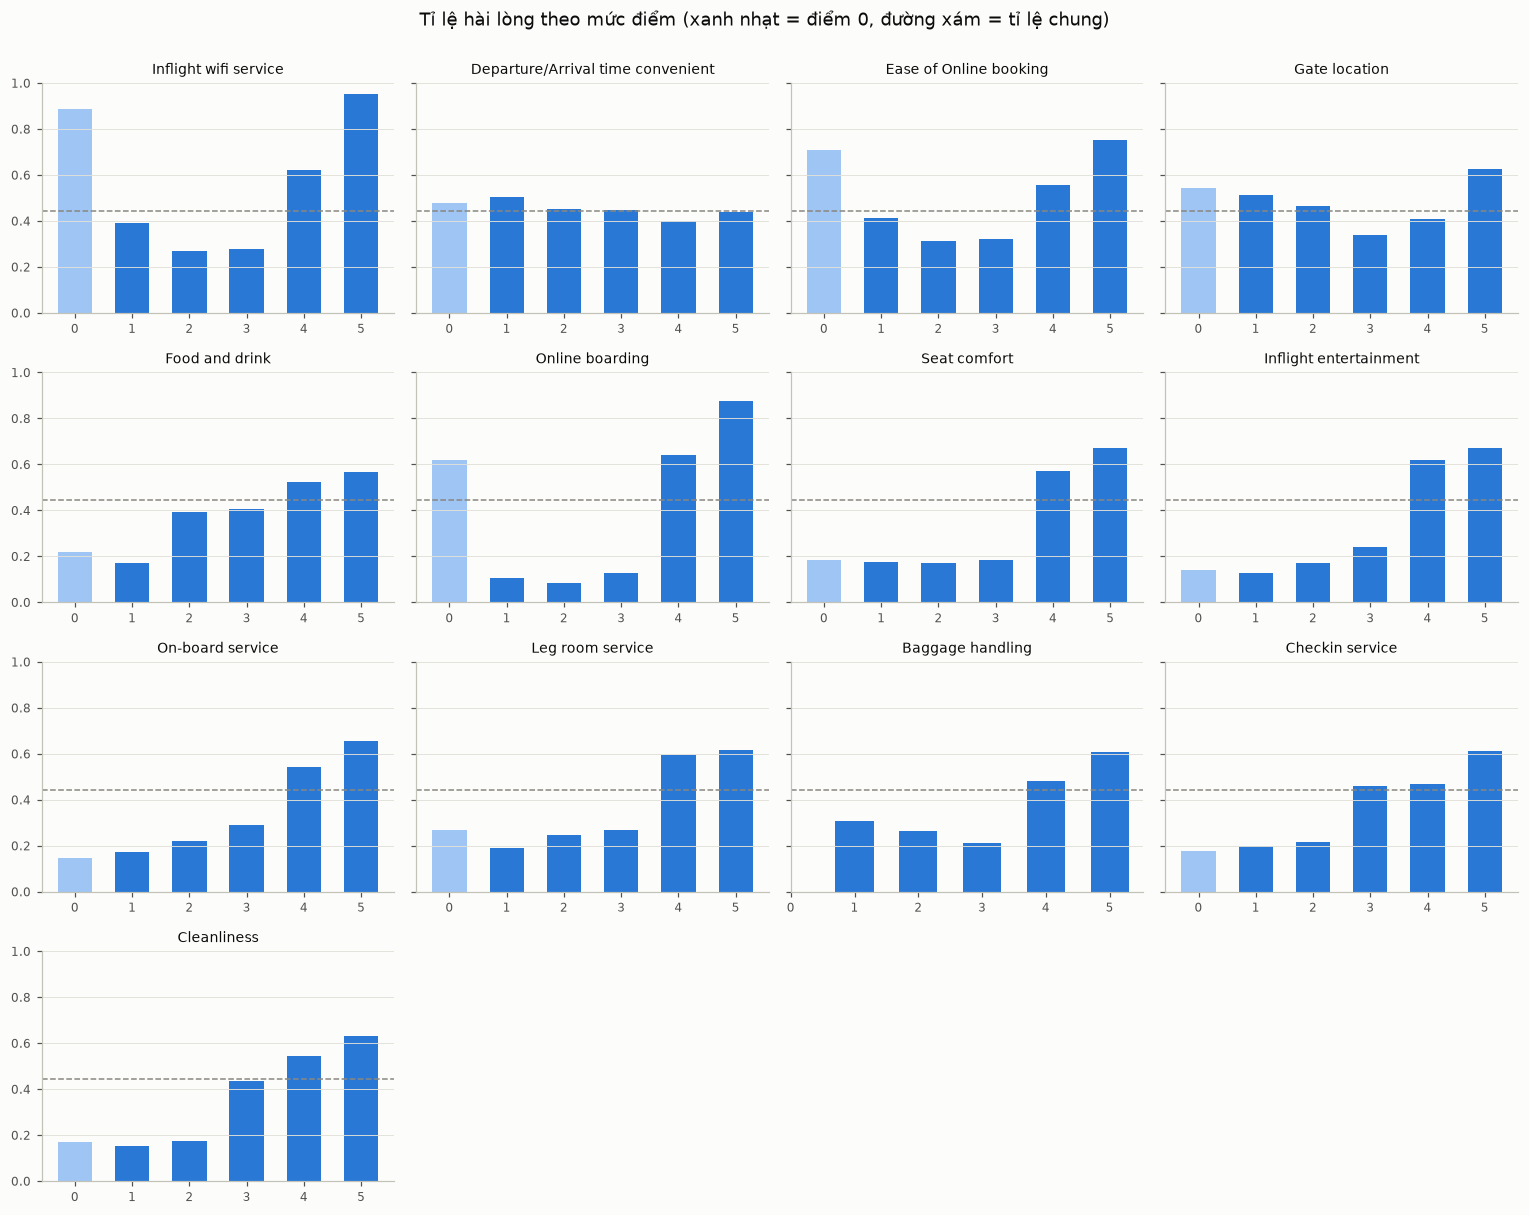

,rate@0,n@0,rate@1,rate@3,rate@5,rate@5 - rate@1
Online boarding,0.620,9147.0,0.105,0.128,0.875,0.770
Inflight wifi service,0.887,13102.0,0.391,0.276,0.950,0.560
Inflight entertainment,0.140,1020.0,0.127,0.239,0.671,0.544
Seat comfort,0.184,838.0,0.174,0.185,0.671,0.497
On-board service,0.147,801.0,0.174,0.291,0.657,0.482
Cleanliness,0.168,945.0,0.155,0.437,0.630,0.476
Leg room service,0.270,1693.0,0.189,0.266,0.615,0.426
Checkin service,0.179,929.0,0.199,0.460,0.610,0.411
Food and drink,0.219,1014.0,0.171,0.407,0.565,0.395
Ease of Online booking,0.708,16073.0,0.415,0.320,0.754,0.340


In [9]:
fig, axes = plt.subplots(4, 4, figsize=(14, 11), sharey=True)
score_tab = {}
for ax, col in zip(axes.flat, SCORE_COLS):
    t = rate_table(col)
    score_tab[col] = t
    colors = [BLUE_LIGHT if s == 0 else BLUE for s in t.index]
    ax.bar(t.index, t["rate"], color=colors, width=0.6)
    ax.axhline(BASE, color=REF, lw=1, ls="--")
    ax.set_title(col, fontsize=9)
    ax.set_xticks(range(6))
    ax.set_ylim(0, 1)
    ax.grid(axis="x", visible=False)
for ax in axes.flat[len(SCORE_COLS):]:
    ax.axis("off")
fig.suptitle("Tỉ lệ hài lòng theo mức điểm (xanh nhạt = điểm 0, đường xám = tỉ lệ chung)", y=1.0)
fig.tight_layout()
save(fig, "02_score_rate")
plt.show()

summary = pd.DataFrame({
    col: {
        "rate@0": t["rate"].get(0, np.nan), "n@0": t["n"].get(0, 0),
        "rate@1": t["rate"].get(1), "rate@3": t["rate"].get(3), "rate@5": t["rate"].get(5),
        "rate@5 - rate@1": t["rate"].get(5) - t["rate"].get(1),
    } for col, t in score_tab.items()
}).T.sort_values("rate@5 - rate@1", ascending=False)
summary.round(3)

## 4. Cột số: tuổi, quãng đường, delay

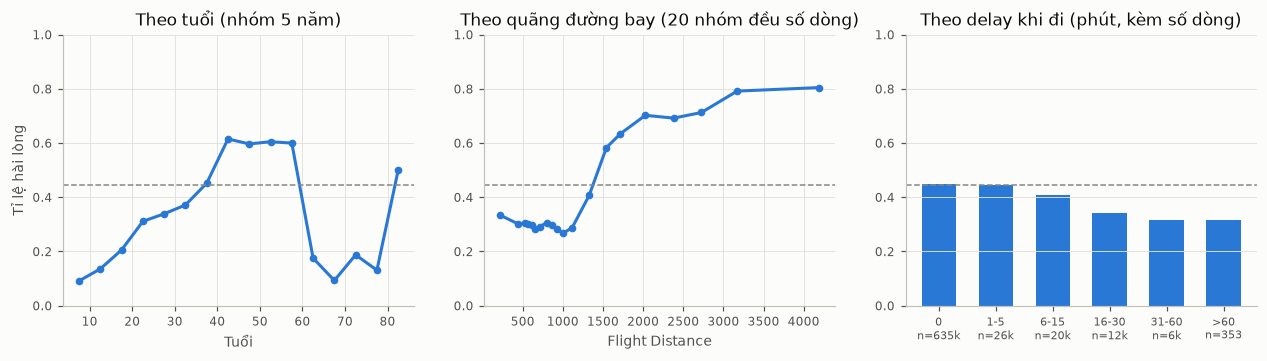

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))

age = train.groupby(pd.cut(train["Age"], range(5, 90, 5)), observed=True)[TARGET].mean()
axes[0].plot([iv.mid for iv in age.index], age.values, color=BLUE, lw=2, marker="o", ms=4)
axes[0].set_title("Theo tuổi (nhóm 5 năm)")
axes[0].set_xlabel("Tuổi")

dist = train.groupby(pd.qcut(train["Flight Distance"], 20), observed=True)[TARGET].mean()
axes[1].plot([iv.mid for iv in dist.index], dist.values, color=BLUE, lw=2, marker="o", ms=4)
axes[1].set_title("Theo quãng đường bay (20 nhóm đều số dòng)")
axes[1].set_xlabel("Flight Distance")

bins = [-1, 0, 5, 15, 30, 60, 10_000]
labels = ["0", "1-5", "6-15", "16-30", "31-60", ">60"]
d = train.groupby(pd.cut(train["Departure Delay in Minutes"], bins, labels=labels), observed=True)[TARGET].agg(["mean", "size"])
axes[2].bar([f"{lab}\nn={n / 1000:.0f}k" if n >= 1000 else f"{lab}\nn={n}" for lab, n in zip(d.index.astype(str), d["size"])], d["mean"], color=BLUE, width=0.6)
axes[2].tick_params(axis="x", labelsize=7)
axes[2].set_title("Theo delay khi đi (phút, kèm số dòng)")
axes[2].grid(axis="x", visible=False)

for ax in axes:
    ax.axhline(BASE, color=REF, lw=1, ls="--")
    ax.set_ylim(0, 1)
axes[0].set_ylabel("Tỉ lệ hài lòng")
save(fig, "03_numeric_rate")
plt.show()

In [11]:
dep, arr = train["Departure Delay in Minutes"], train["Arrival Delay in Minutes"]
print("Tỉ lệ dòng delay đi = 0:", f"{(dep == 0).mean():.2%}", "| delay đến = 0:", f"{(arr == 0).mean():.2%}")
print("Tương quan Spearman delay đi vs đến:", round(dep.corr(arr, method="spearman"), 3))
diff = (arr - dep).dropna()
print("Chênh lệch (đến - đi): tỉ lệ = 0:", f"{(diff == 0).mean():.2%}")
print(diff.describe().round(2))
print("\nDòng thiếu Arrival Delay: delay đi =", train.loc[arr.isna(), "Departure Delay in Minutes"].describe()[["mean", "50%", "max"]].to_dict(),
      "| tỉ lệ hài lòng:", round(train.loc[arr.isna(), TARGET].mean(), 4))

Tỉ lệ dòng delay đi = 0: 90.78% | delay đến = 0: 91.54%
Tương quan Spearman delay đi vs đến: 0.472
Chênh lệch (đến - đi): tỉ lệ = 0: 86.90%
count    699343.00
mean         -0.04
std           3.30
min         -39.00
25%           0.00
50%           0.00
75%           0.00
max          91.00
dtype: float64

Dòng thiếu Arrival Delay: delay đi = {'mean': 7.434931506849315, '50%': 0.0, 'max': 202.0} | tỉ lệ hài lòng: 0.363


## 5. Độ mạnh từng cột: AUC khi chỉ dùng một cột

Với cột số và cột điểm: dùng thẳng giá trị làm điểm dự đoán (nếu cột tỉ lệ nghịch thì lấy 1 - AUC). Với cột category: thay mỗi giá trị bằng tỉ lệ hài lòng của nó. AUC 0,5 là vô dụng, càng gần 1 càng mạnh.

Chú ý: AUC thấp khi đứng một mình không có nghĩa cột vô dụng, vì có thể mạnh khi kết hợp với cột khác.

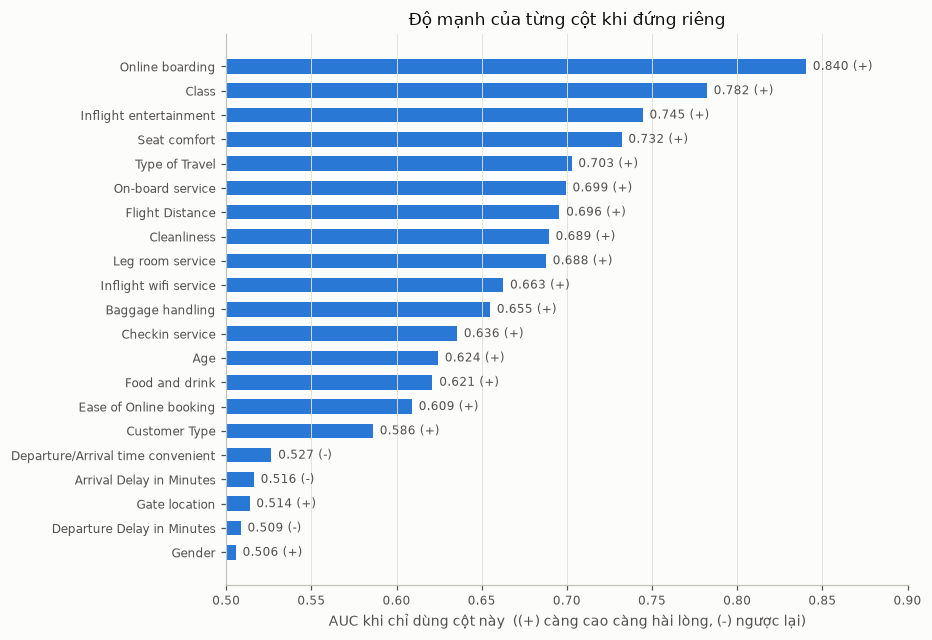

,feature,auc,chiều
20,Online boarding,0.8404,+
19,Class,0.7822,+
18,Inflight entertainment,0.7445,+
17,Seat comfort,0.7321,+
16,Type of Travel,0.7027,+
15,On-board service,0.6993,+
14,Flight Distance,0.6956,+
13,Cleanliness,0.6894,+
12,Leg room service,0.6877,+
11,Inflight wifi service,0.6627,+


In [12]:
rows = []
for col in CAT_COLS + SCORE_COLS + NUM_COLS:
    x = train[col]
    if col in CAT_COLS:
        x = x.map(train.groupby(col)[TARGET].mean())
    x = x.fillna(x.median())
    auc = roc_auc_score(y, x)
    rows.append({"feature": col, "auc": max(auc, 1 - auc), "chiều": "+" if auc >= 0.5 else "-"})
uni = pd.DataFrame(rows).sort_values("auc").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(uni["feature"], uni["auc"] - 0.5, left=0.5, color=BLUE, height=0.6)
for i, (a, s) in enumerate(zip(uni["auc"], uni["chiều"])):
    ax.text(a + 0.004, i, f"{a:.3f} ({s})", va="center", fontsize=8, color="#52514e")
ax.set_xlim(0.5, max(uni["auc"]) + 0.06)
ax.set_xlabel("AUC khi chỉ dùng cột này  ((+) càng cao càng hài lòng, (-) ngược lại)")
ax.set_title("Độ mạnh của từng cột khi đứng riêng")
ax.grid(axis="y", visible=False)
save(fig, "04_univariate_auc")
plt.show()
uni.sort_values("auc", ascending=False).round(4)

## 6. Tương quan giữa các cột (Spearman)

Xanh là tương quan dương, đỏ là âm, xám là gần 0. Cặp tương quan cao là ứng viên để gộp (trung bình, chênh lệch).

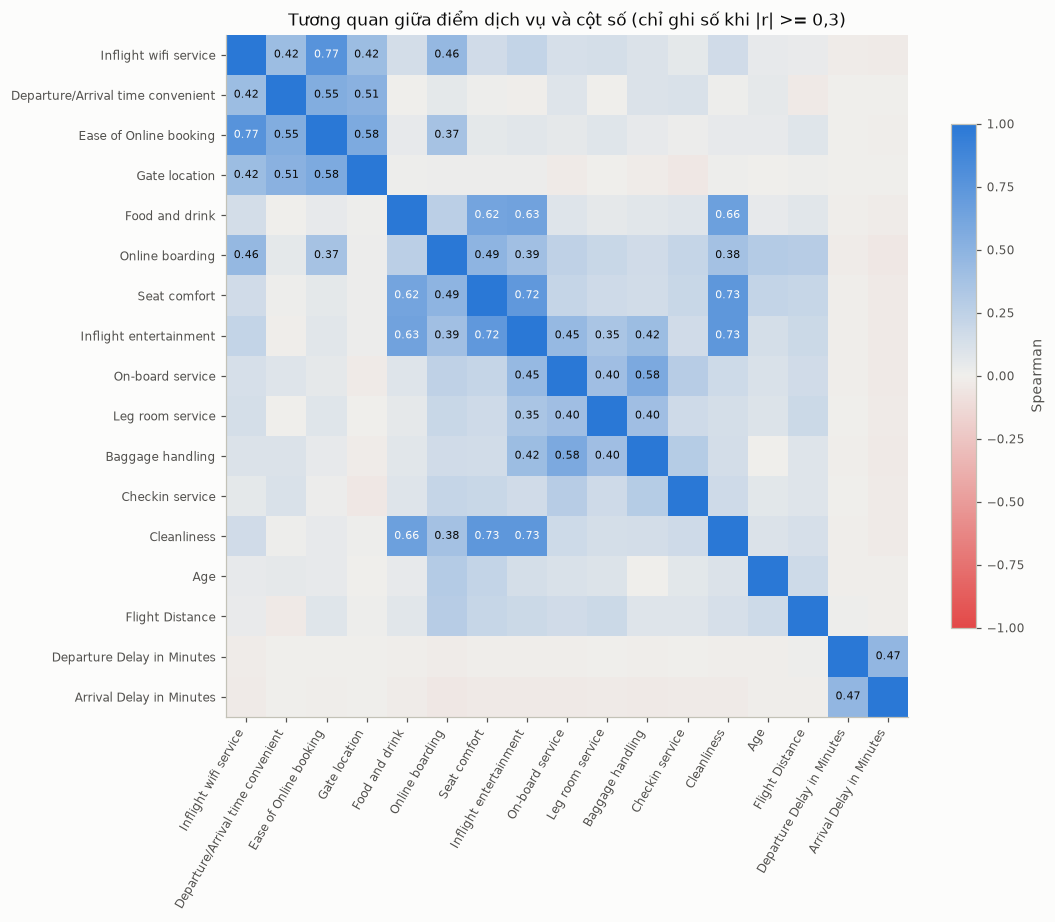

,level_0,level_1,r,abs_r
1,Inflight wifi service,Ease of Online booking,0.770,0.770
86,Seat comfort,Cleanliness,0.733,0.733
95,Inflight entertainment,Cleanliness,0.727,0.727
81,Seat comfort,Inflight entertainment,0.723,0.723
65,Food and drink,Cleanliness,0.657,0.657
60,Food and drink,Inflight entertainment,0.633,0.633
59,Food and drink,Seat comfort,0.620,0.620
101,On-board service,Baggage handling,0.581,0.581
31,Ease of Online booking,Gate location,0.577,0.577
16,Departure/Arrival time convenient,Ease of Online booking,0.549,0.549


In [13]:
from matplotlib.colors import LinearSegmentedColormap

cols = SCORE_COLS + NUM_COLS
corr = train[cols].corr(method="spearman")
cmap = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr.values, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=60, ha="right")
ax.set_yticks(range(len(cols)), cols)
ax.grid(False)
for i in range(len(cols)):
    for j in range(len(cols)):
        v = corr.values[i, j]
        if i != j and abs(v) >= 0.3:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                    color="#fcfcfb" if abs(v) >= 0.6 else "#0b0b0b")
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman")
ax.set_title("Tương quan giữa điểm dịch vụ và cột số (chỉ ghi số khi |r| >= 0,3)")
save(fig, "05_correlation")
plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("r").reset_index().assign(abs_r=lambda d: d["r"].abs())
         .sort_values("abs_r", ascending=False))
pairs.head(12).round(3)

## 7. Tương tác giữa các cột category

Tỉ lệ hài lòng theo từng tổ hợp. Nếu tỉ lệ của một tổ hợp khác hẳn những gì từng cột riêng gợi ý, đó là dấu hiệu nên tạo feature ghép.

In [14]:
for a, b in [("Class", "Type of Travel"), ("Customer Type", "Type of Travel"), ("Customer Type", "Class")]:
    t = train.pivot_table(index=a, columns=b, values=TARGET, aggfunc=["mean", "size"])
    print(f"--- {a} × {b} ---")
    print(t.round(3), "\n")

--- Class × Type of Travel ---
                          mean                            size                
Type of Travel Business travel Personal Travel Business travel Personal Travel
Class                                                                         
Business                 0.732           0.112          338272            3940
Eco                      0.260           0.097          141612          185792
Eco Plus                 0.346           0.095           17557           12462 

--- Customer Type × Type of Travel ---
                             mean                            size                
Type of Travel    Business travel Personal Travel Business travel Personal Travel
Customer Type                                                                    
Loyal Customer              0.710           0.097          374901          202089
disloyal Customer           0.201           0.114          122540             105 



--- Customer Type × Class ---
                      mean                     size                 
Class             Business    Eco Eco Plus Business     Eco Eco Plus
Customer Type                                                       
Loyal Customer       0.783  0.179    0.259   298315  251233    27442
disloyal Customer    0.335  0.128    0.064    43897   76171     2577 



## 8. Adversarial validation

Gộp train và test, gắn nhãn 0 = train, 1 = test, rồi train LightGBM phân biệt hai bên (5 fold). AUC gần 0,5 nghĩa là không phân biệt được, tức train và test cùng phân phối. Nếu cao hơn khoảng 0,55 thì xem cột nào gây lệch.

In [15]:
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold

feats = CAT_COLS + SCORE_COLS + NUM_COLS
both = pd.concat([train[feats], test[feats]], ignore_index=True)
for c in CAT_COLS:
    both[c] = both[c].astype("category")
is_test = np.r_[np.zeros(len(train)), np.ones(len(test))]

pred = np.zeros(len(both))
imp = pd.Series(0.0, index=feats)
for tr, va in StratifiedKFold(5, shuffle=True, random_state=42).split(both, is_test):
    m = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.1, num_leaves=63, verbose=-1, random_state=42)
    m.fit(both.iloc[tr], is_test[tr])
    pred[va] = m.predict_proba(both.iloc[va])[:, 1]
    imp += pd.Series(m.booster_.feature_importance("gain"), index=feats) / 5

print(f"Adversarial AUC = {roc_auc_score(is_test, pred):.4f}")
(imp / imp.sum()).sort_values(ascending=False).head(8).round(3)

Adversarial AUC = 0.4995


Flight Distance               0.197
Age                           0.149
Arrival Delay in Minutes      0.059
Departure Delay in Minutes    0.055
Checkin service               0.051
Leg room service              0.047
On-board service              0.042
Gate location                 0.042
dtype: float64

## 9. Tóm tắt cho nhóm

(Điền sau khi chạy, xem bản tóm tắt trong `reports/EDA_summary.md`.)